In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(67)

# Домашняя работа
## Боталова Валерия

---

### Задание 1. Проверка гипотезы о среднем значении

Продукт считает, что среднее время на карточке вакансии равно 120 секунд. Собрали выборку из 100 пользователей, среднее время составило 124 секунды. Разброс одного наблюдения в генеральной совокупности известен заранее и равен 25 секундам.

**Необходимо:**
1. Сформулировать нулевую гипотезу $H_0$.
2. Посчитать, на сколько стандартных ошибок оценка ушла от 120.
3. Решить, есть ли основание отвергать $H_0$.

**Решение**
1. Нулевая гипотеза - среднее вреся на карточке вакансии 120 секунд.
2. SE = 25/sqrt(100) = 25/10 = 2,5
   Выборочное среднее - 124, ожидаемое - 120. Разница в 4 секунды.
   Z = 4/SE = 4/2,5 = 1,6
3. Пусть a = 0,05. Тогда критическое значение +- 1,96. Z меньше крит. значения, а значит нулевую гипотезу нет оснований опровергать.
---

### Задание 2. Сравнение средних двух независимых групп

Даны две независимые группы:

- **Первая группа:** $n_1 = 40$, $\bar{x}_1 = 50$, выборочное среднеквадратическое отклонение $s_1 = 10$.
- **Вторая группа:** $n_2 = 40$, $\bar{x}_2 = 55$, $s_2 = 10$.

Генеральные разбросы двух групп неизвестны и равными их считать не нужно.

**Необходимо:**
1. Посчитать разницу средних.
2. Рассчитать 95% доверительный интервал для разницы средних.
3. Определить, попадает ли 0 в доверительный интервал.
4. Найти самый маленький эффект, который ещё согласуется с данными (то есть не будет отвергать $H_0$).

---

In [2]:
n1, n2 = 40, 40
mean1, mean2 = 50, 55
s1, s2 = 10, 10

diff = mean2 - mean1

se = np.sqrt(s1**2 / n1 + s2**2 / n2)

df = (s1**2/n1 + s2**2/n2)**2 / (
    (s1**2/n1)**2 / (n1-1) +
    (s2**2/n2)**2 / (n2-1)
)

t_crit = stats.t.ppf(0.975, df)

lower = diff - t_crit * se
upper = diff + t_crit * se

min_effect = lower

print(f"Разница средних: {diff:.2f}")
print(f"Стандартная ошибка: {se:.2f}")
print(f"Степени свободы: {df:.2f}")
print(f"Критическое значение t: {t_crit:.3f}")
print(f"Доверительный интервал: [{lower:.2f}; {upper:.2f}]")
print("0 не попадает в доверительный интервал.")
print(f"Минимальный эффект: {min_effect:.2f}")

Разница средних: 5.00
Стандартная ошибка: 2.24
Степени свободы: 78.00
Критическое значение t: 1.991
Доверительный интервал: [0.55; 9.45]
0 не попадает в доверительный интервал.
Минимальный эффект: 0.55


### Задание 3. Проверка гипотезы о двух конверсиях

Проводится сравнение конверсии двух независимых групп:

- **Первая группа:** 90 откликов на 1000 показов карточки.
- **Вторая группа:** 120 откликов на 1000 показов карточки.

Каждый показ относится к своему пользователю, группы независимы.

**Необходимо:**
1. Сформулировать нулевую гипотезу $H_0$ для двух конверсий.
2. Посчитать разницу конверсий в процентных пунктах.
3. Рассчитать статистику критерия для двух долей.
4. Решить, есть ли основание отвергать $H_0$.

---

In [3]:
n1,n2 = 1000, 1000
responses1, responses2 = 90, 120

print("Нулевая гипотеза - различий между группами нет, конверсии одинаковые.")

conversion1 = responses1 / n1
conversion2 = responses2 / n2
diff = conversion2 - conversion1
print(f"Разница конверсий - {diff * 100} п.п.")

conversion = (responses1 + responses2) / (n1 + n2)
se = math.sqrt(conversion * (1 - conversion) * (1/n1 + 1/n2))
z = diff / se
print(f'z-статистика: {z:.2f}')

z_crit = 1.96
print(f"Так как z-стат равный {z:.2f} больше {z_crit}, мы отвергаем нулевую гипотезу. Конверсии не одинаковы." )

Нулевая гипотеза - различий между группами нет, конверсии одинаковые.
Разница конверсий - 3.0 п.п.
z-статистика: 2.19
Так как z-стат равный 2.19 больше 1.96, мы отвергаем нулевую гипотезу. Конверсии не одинаковы.


### Задание 4. Распределение p-value при верной нулевой гипотезе

Повторите эксперимент 2000 раз.

В каждом повторе заново наберите две группы по $n = 200$ наблюдений из одного и того же нормального распределения $N(0, 1)$.

На каждой паре групп посчитайте t-критерий Уэлча и его p-value.

**Необходимо:**
1. Повторить эксперимент 2000 раз.
2. В каждом повторе рассчитать t-критерий Уэлча и p-value.
3. Построить распределение p-value.
4. Описать, какую форму имеет полученное распределение и почему.

---


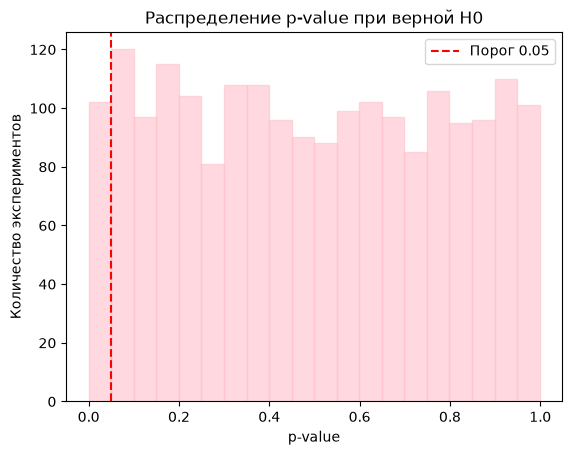

Было получено распределение p-value, близкое к равномерному на интервале от 0 до 1. обе группы генерируются из одного и того же нормального распределения N(0, 1), поэтому нулевая гипотеза верна. При выполнении корректного статистического теста p-value при верной нулевой гипотезе имеют равномерное распределение.


In [4]:
# Для генератора было взято число 67
mu, sigma, size = 0, 1, 200
n_simulations = 2000
t_values = []
p_values = []

for i in range(n_simulations):
    group1 = rng.normal(mu, sigma, size)
    group2 = rng.normal(mu, sigma, size)

    result = stats.ttest_ind(group1, group2, equal_var=False)
    t_values.append(result.statistic)
    p_values.append(result.pvalue)

plt.hist(p_values, bins=20, alpha=0.6, color='pink', edgecolor='pink')
plt.axvline(0.05, color="red", linestyle="--", label="Порог 0.05")

plt.title("Распределение p-value при верной H0")
plt.xlabel("p-value")
plt.ylabel("Количество экспериментов")
plt.legend()
plt.show()

print("Было получено распределение p-value, близкое к равномерному на интервале от 0 до 1. обе группы генерируются из одного и того же нормального распределения N(0, 1), поэтому нулевая гипотеза верна. При выполнении корректного статистического теста p-value при верной нулевой гипотезе имеют равномерное распределение.")

### Задание 5. Сравнение t-критерия и критерия Манна — Уитни

Повторите эксперимент 1000 раз.

В каждом повторе:

- Первую группу генерируйте из $N(0, 1)$, размер выборки — $n = 60$.
- Вторую группу генерируйте из $N(1, 1)$, размер выборки — $n = 60$.
- После генерации замените два наблюдения второй группы на $-50$.

На каждой паре групп рассчитайте:
- разницу средних;
- t-критерий Уэлча;
- U-критерий Манна — Уитни для первой группы;
- p-value обоих критериев.

**Необходимо:**
1. Повторить эксперимент 1000 раз.
2. Построить распределения статистик t и U.
3. Построить распределения p-value обоих критериев.
4. Отметить на графиках пороговое значение $0{,}05$.
5. Сравнить, где сосредоточены значения p-value.
6. Определить, какое решение принимает каждый критерий при двустороннем пороге значимости 5%.
7. Установить, совпали ли выводы критериев или разошлись, и объяснить почему.

---


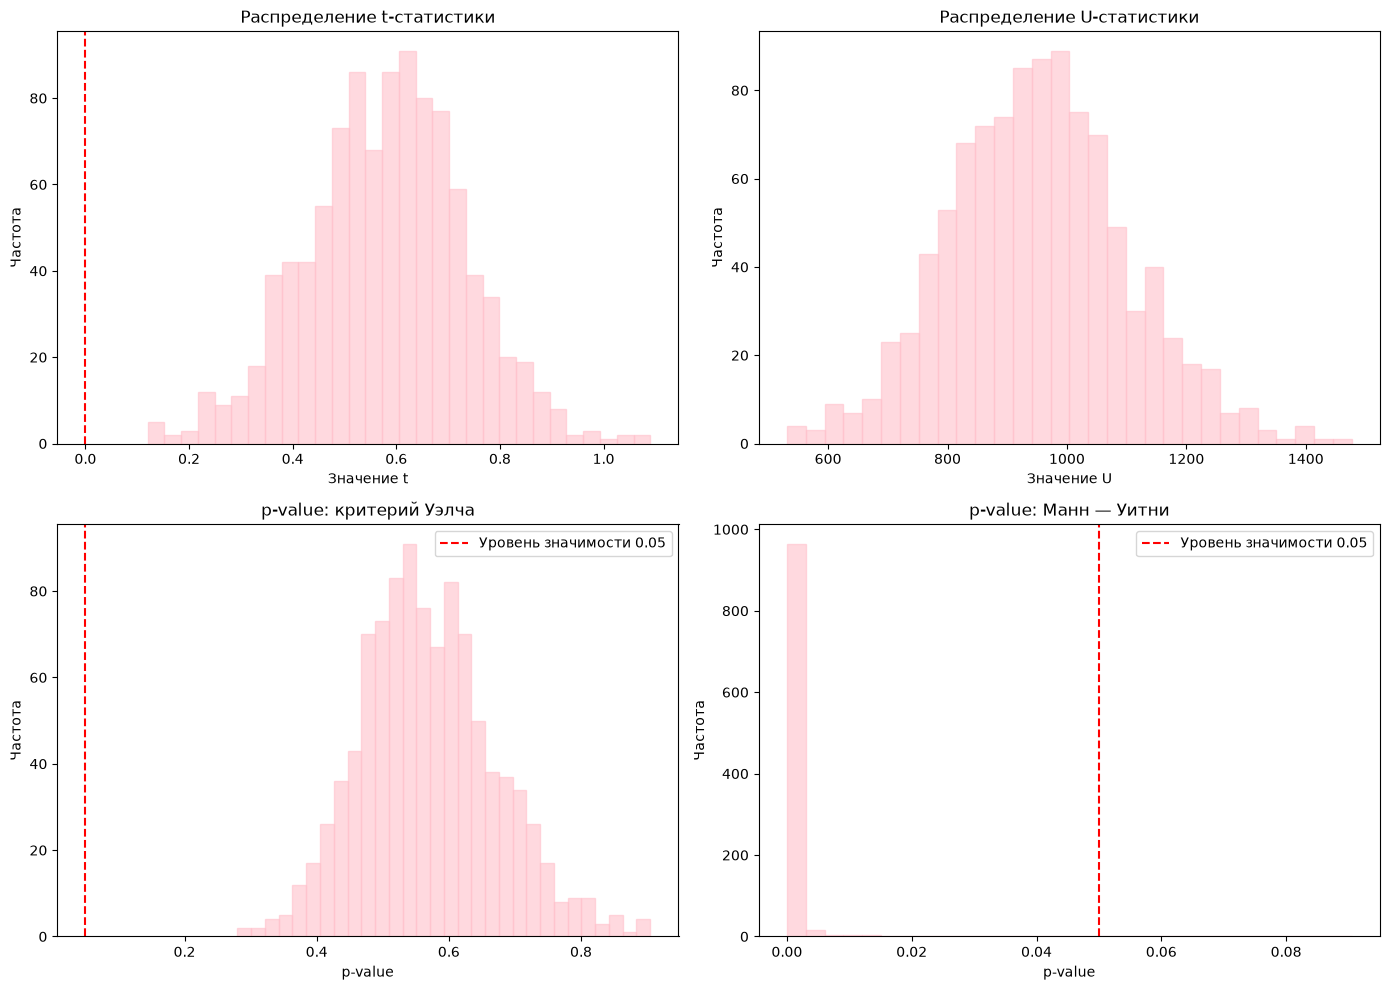

РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА

Средняя разница средних: -0.6979740576010091

Критерий Уэлча:
Среднее p-value: 0.5690644441098778
Доля значимых результатов: 0.0 %

Критерий Манна — Уитни:
Среднее p-value: 0.0006393799887464324
Доля значимых результатов: 99.8 %

СРАВНЕНИЕ КРИТЕРИЕВ
Оба критерия нашли значимость: 0
Оба критерия не нашли значимость: 2
Выводы критериев разошлись: 998

Доля совпадений: 0.2 %


In [5]:
n_simulations = 1000
mu1, sigma1, size1 = 0, 1, 60
mu2, sigma2, size2 = 1, 1, 60
replaced_value = -50

mean_differences = []
t_statistics = []
u_statistics = []
t_pvalues = []
u_pvalues = []

for i in range(n_simulations):
    group1 = rng.normal(mu1, sigma1, size1)
    group2 = rng.normal(mu2, sigma2, size2)

    indices = rng.choice(size2, size = 2, replace = False)
    group2[indices] = replaced_value

    mean_differences.append(np.mean(group2) - np.mean(group1))
    t_stat, t_p = stats.ttest_ind(group1, group2, equal_var = False)
    t_statistics.append(t_stat)
    t_pvalues.append(t_p)

    u_stat, u_p = stats.mannwhitneyu(group1, group2, alternative = 'two-sided')

    u_statistics.append(u_stat)
    u_pvalues.append(u_p)

mean_differences = np.array(mean_differences)
t_statistics = np.array(t_statistics)
u_statistics = np.array(u_statistics)
t_pvalues = np.array(t_pvalues)
u_pvalues = np.array(u_pvalues)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(t_statistics, bins=30, alpha=0.6, color='pink', edgecolor='pink')
axes[0, 0].set_title('Распределение t-статистики')
axes[0, 0].set_xlabel('Значение t')
axes[0, 0].set_ylabel('Частота')
axes[0, 0].axvline(0, color='red', linestyle='--')

axes[0, 1].hist(u_statistics, bins=30, alpha=0.6, color='pink', edgecolor='pink')
axes[0, 1].set_title('Распределение U-статистики')
axes[0, 1].set_xlabel('Значение U')
axes[0, 1].set_ylabel('Частота')

axes[1, 0].hist(t_pvalues, bins=30,  alpha=0.6, color='pink', edgecolor='pink')
axes[1, 0].axvline(0.05, color='red', linestyle='--', label='Уровень значимости 0.05')
axes[1, 0].set_title('p-value: критерий Уэлча')
axes[1, 0].set_xlabel('p-value')
axes[1, 0].set_ylabel('Частота')
axes[1, 0].legend()

axes[1, 1].hist(u_pvalues, bins=30, alpha=0.6, color='pink', edgecolor='pink')
axes[1, 1].axvline(0.05, color='red', linestyle='--', label='Уровень значимости 0.05')
axes[1, 1].set_title('p-value: Манн — Уитни')
axes[1, 1].set_xlabel('p-value')
axes[1, 1].set_ylabel('Частота')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

alpha = 0.05

t_significant = t_pvalues < alpha
u_significant = u_pvalues < alpha

print('РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА')
print('\nСредняя разница средних:',
      np.mean(mean_differences))

print('\nКритерий Уэлча:')
print('Среднее p-value:', np.mean(t_pvalues))
print('Доля значимых результатов:',
      np.mean(t_significant) * 100, '%')

print('\nКритерий Манна — Уитни:')
print('Среднее p-value:', np.mean(u_pvalues))
print('Доля значимых результатов:',
      np.mean(u_significant) * 100, '%')

both_significant = np.sum(t_significant & u_significant)
both_not_significant = np.sum(~t_significant & ~u_significant)
different = np.sum(t_significant != u_significant)

print('\nСРАВНЕНИЕ КРИТЕРИЕВ')
print('Оба критерия нашли значимость:', both_significant)
print('Оба критерия не нашли значимость:', both_not_significant)
print('Выводы критериев разошлись:', different)

print('\nДоля совпадений:',
      (n_simulations - different) / n_simulations * 100, '%')

### Задание 6. Доверительный интервал Уэлча

Один раз сгенерируйте две группы:

- **Первая группа:** $N(10, 2)$, $n_1 = 80$.
- **Вторая группа:** $N(10{,}8, 2{,}6)$, $n_2 = 75$.

**Необходимо:**
1. Рассчитать 95% доверительный интервал Уэлча для разницы средних «вторая минус первая».
2. Рассчитать p-value критерия Уэлча.
3. Решить, есть ли основание отвергать $H_0$ при двустороннем пороге значимости 5%.
4. Определить, попадает ли 0 в доверительный интервал.
5. Найти самый маленький эффект, который ещё согласуется с данными (не отвергает $H_0$).

---

In [6]:
group1 = rng.normal(10, 2, 80)
group2 = rng.normal(10.8, 2.6, 75)

mean1 = np.mean(group1)
mean2 = np.mean(group2)

difference = mean2 - mean1

print('Среднее первой группы:', mean1)
print('Среднее второй группы:', mean2)
print('Разница средних:', difference)

n1 = len(group1)
n2 = len(group2)

var1 = np.var(group1, ddof=1)
var2 = np.var(group2, ddof=1)

se = np.sqrt(var1 / n1 + var2 / n2)

df = (var1/n1 + var2/n2)**2 / ( (var1/n1)**2 / (n1-1) + (var2/n2)**2 / (n2-1) )

t_critical = stats.t.ppf(0.975, df)

ci_lower = float(difference - t_critical * se)
ci_upper = float(difference + t_critical * se)

print('Стандартная ошибка:', se)
print('Степени свободы:', df)
print('95% доверительный интервал:', (ci_lower, ci_upper))

t_stat, p_value = stats.ttest_ind(group2, group1, equal_var=False, alternative='two-sided')

print('t-статистика:', t_stat)
print('p-value:', p_value)

alpha = 0.05

if p_value < alpha:
    print('Отвергаем H0: различие статистически значимо')
else:
    print('Не отвергаем H0: недостаточно оснований считать различие статистически значимым')

if ci_lower <= 0 <= ci_upper:
    print('0 входит в доверительный интервал')
else:
    print('0 не входит в доверительный интервал')

Среднее первой группы: 10.030368068325343
Среднее второй группы: 10.333168007201142
Разница средних: 0.3027999388757987
Стандартная ошибка: 0.4171648521755328
Степени свободы: 142.158014887083
95% доверительный интервал: (-0.5218482494863035, 1.1274481272379009)
t-статистика: 0.7258519918365218
p-value: 0.46912281738653155
Не отвергаем H0: недостаточно оснований считать различие статистически значимым
0 входит в доверительный интервал


### Задание 7. Bootstrap и сравнение доверительных интервалов

Возьмите те же две группы, что и в предыдущем задании.

2000 раз заново соберите выборки того же размера: каждый раз берите наблюдения из уже полученных групп с возвращением.

В NumPy для этого используется `rng.choice` с параметром `replace=True`.

Заново рассчитывайте разницу средних для каждой повторной выборки.

**Необходимо:**
1. Выполнить 2000 повторных выборок с возвращением.
2. Построить распределение полученных разниц средних.
3. Рассчитать 95% bootstrap-интервал — границы, отсекающие по 2,5% значений с каждого края.
4. Сравнить эти границы с доверительным интервалом из предыдущего задания.
5. Отдельно посчитать, в какой доле повторных выборок разница получилась не больше нуля.
6. Определить, можно ли эту долю назвать p-value, и объяснить почему.

---

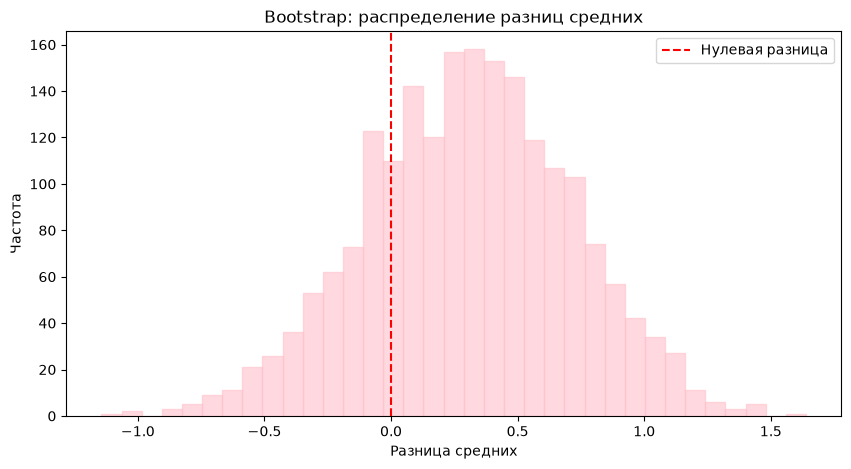

Bootstrap-интервал:
-0.5166255144978164 1.0859448668169256

Интервал Уэлча:
-0.5218482494863035 1.1274481272379009

Bootstrap-интервал:
-0.5166255144978164 1.0859448668169256

Количество разниц <= 0: 467
Доля разниц <= 0: 0.2335
Процент: 23.35 %


In [9]:
n_bootstrap = 2000
bootstrap_differences = []

for i in range(n_bootstrap):
    bootstrap_group1 = rng.choice(group1, size=len(group1), replace=True)
    bootstrap_group2 = rng.choice(group2, size=len(group2), replace=True)
    difference = np.mean(bootstrap_group2) - np.mean(bootstrap_group1)
    bootstrap_differences.append(difference)

plt.figure(figsize=(10, 5))
plt.hist(bootstrap_differences, bins=35, alpha=0.6, color='pink', edgecolor='pink')
plt.axvline(0, color='red', linestyle='--',label='Нулевая разница')
plt.title('Bootstrap: распределение разниц средних')
plt.xlabel('Разница средних')
plt.ylabel('Частота')
plt.legend()
plt.show()

bootstrap_ci_lower = np.percentile(bootstrap_differences, 2.5)
bootstrap_ci_upper = np.percentile(bootstrap_differences, 97.5)
print('Bootstrap-интервал:')
print(bootstrap_ci_lower, bootstrap_ci_upper)
print('\nИнтервал Уэлча:')
print(ci_lower, ci_upper)
print('\nBootstrap-интервал:')
print(bootstrap_ci_lower, bootstrap_ci_upper)

count_non_positive = sum(difference <= 0 for difference in bootstrap_differences)
fraction_non_positive = count_non_positive / n_bootstrap
print('\nКоличество разниц <= 0:', count_non_positive)
print('Доля разниц <= 0:', fraction_non_positive)
print('Процент:', fraction_non_positive * 100, '%')

## Итог

После выполнения всех заданий необходимо представить:
- расчёты и результаты статистических тестов;
- графики распределений;
- рассчитанные доверительные интервалы;
- выводы по каждому заданию.
